**Prompt 1:**

hey good afternoon, hope you are doing great. I am working on a project of finding the circuits in LLMs for performing the behavior of distinction objects. Thought something could grab so we can discuss it in details

**Prompt 2:**

Many thanks, I really appreciate the examples and concepts you shared. If you don't mind, I would like to process about the following. The details you have shared really great, please allow me sometime to explore and then we can start working on the things upon completion of the current project.

Here is what I am doing:

Prompt 1: John gave bag to John ---> clean prompt

Prompt 2: John gave bag to Mary. ----> corrupt prompt

The thing that I am exploring is which attention heads or MLPs or specific circuit does the job of separating the John being same person as it is mentioned in the first prompt. How the circuits work to distuinguish the 2 people having same name.

I do have a list of prompts which will be next thing before we can work on the following part of the circuit.

Run the model on paired examples such as:
John gave the bag to John.
and
John gave the bag to Mary.
The essential goal is to patch activations from one run into the other at different layers/positions.

**Prompt 3:**

Wonderful explanation so intelligent. Now that we have a good contextual material, why not start with the coding. I hope we can speak clearly in numbers what did i am reaching is 2 metrics:

Direct Logit Attribution
Logit Attribution.

I do have part of the coding where GPT-2 is already loaded with Transformerlens now just turning to the second part patching on the promots

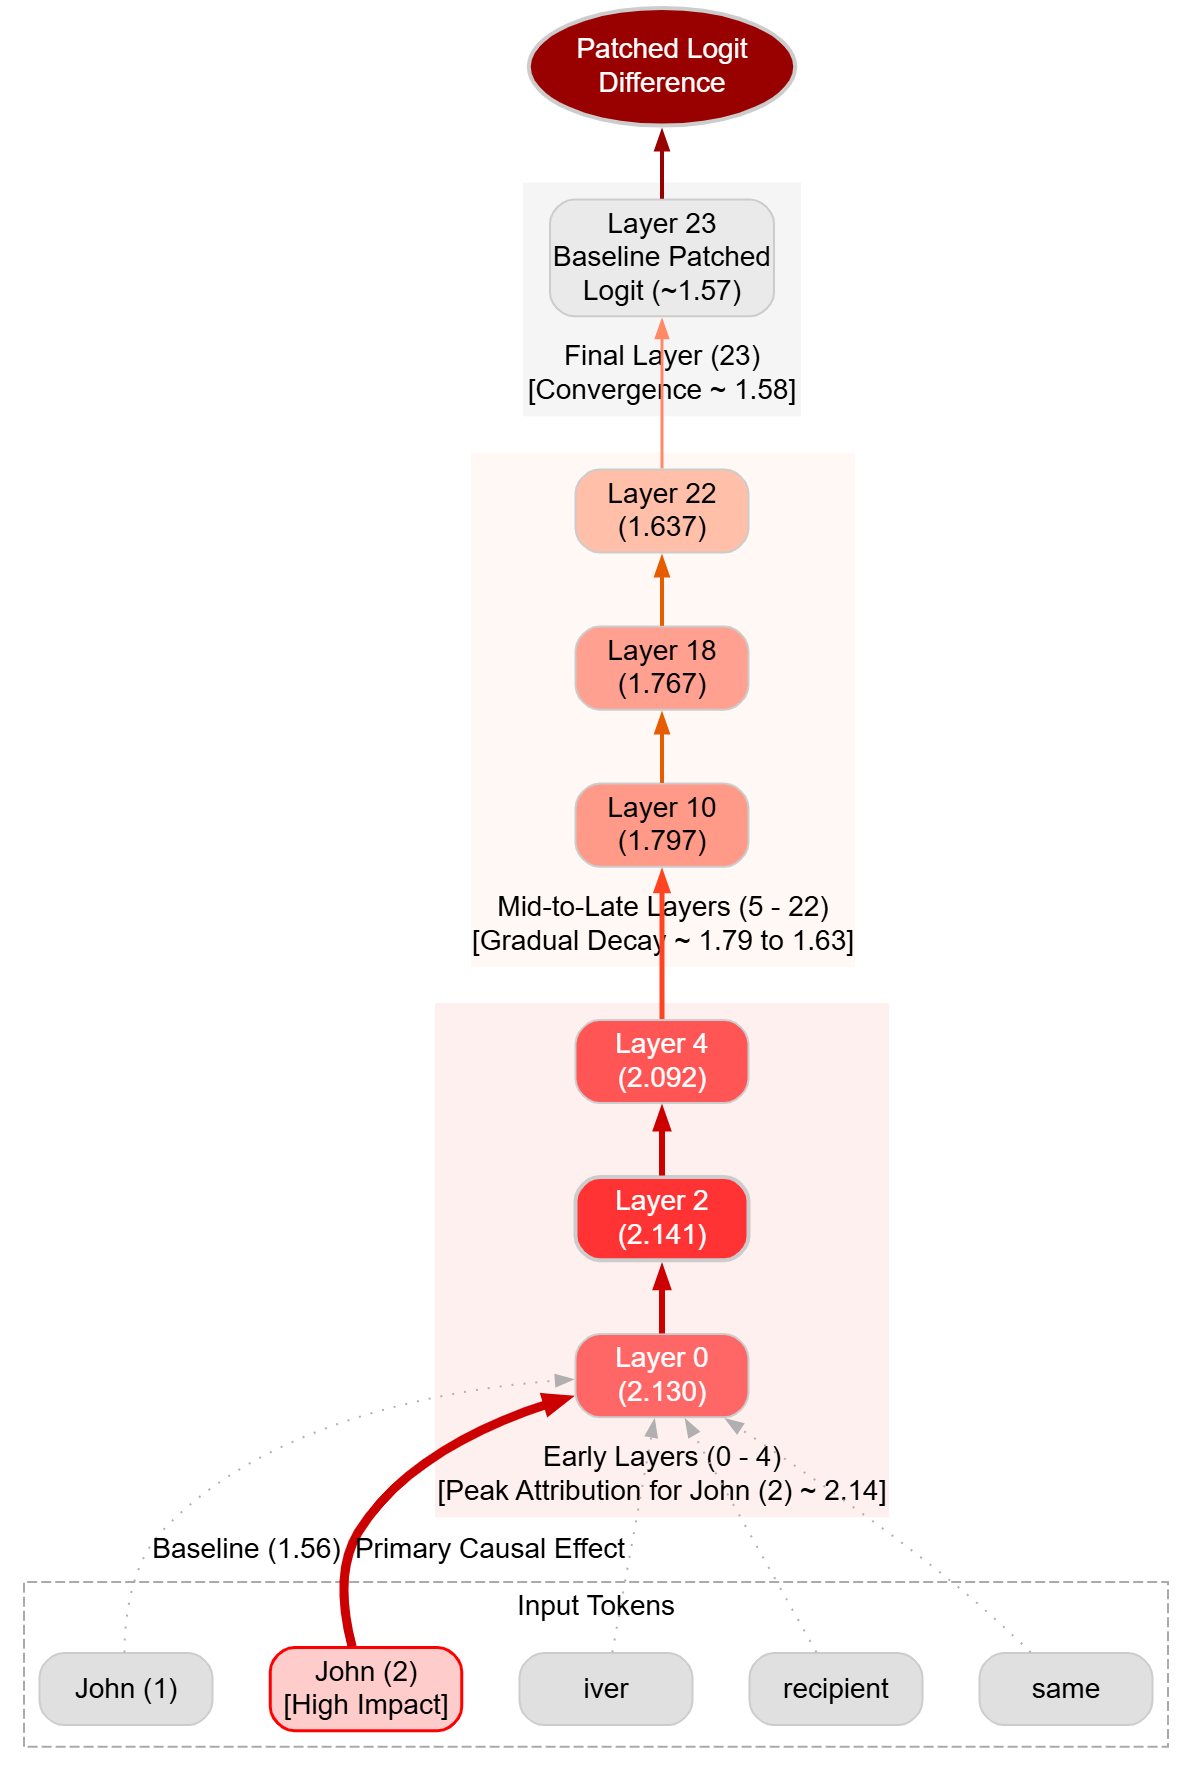

**Which Component of the transformer casually contributing to distinguish the identical entities**


[Numerical Rankings of Entity Separator](https://chatgpt.com/s/t_6ae89ce37b54819182b4abd30290e422)

In [ ]:
!pip install "transformer-lens<4.0"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 34.0 MB/s  0:00:00
  Created wheel for transformers-stream-generator: filename=transformers_stream_generator-0.0.5-py3-none-any.whl size=12526 sha256=2ea139059dcbdf9937fbac4f465b4bd980acc61b1396987885c3fe706ef6c339
  Stored in directory: /root/.cache/pip/wheels/f6/6e/1a/710143d0e50e827ae5b60a47a6d43d715cf1c6e35881a05530
Successfully built transformers-stream-generator
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [transformer-lens]


In [ ]:
import torch
import torch.nn.functional as F
from transformer_lens.model_bridge import TransformerBridge
MODEL_NAME = "gpt2-medium"
TOP_K = 10

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Loading {MODEL_NAME} on {device}...")

model = TransformerBridge.boot_transformers(
    MODEL_NAME,
    device=device,
)

model.eval()

Loading gpt2-medium on cpu...


config.json:   0%|          | 0.00/718 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.52GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

TransformerBridge(
  (embed): EmbeddingBridge(
    (hook_in): HookPoint(name='embed.hook_in')
    (hook_out): HookPoint(name='embed.hook_out')
    (_original_component): Embedding(50257, 1024)
  )
  (pos_embed): PosEmbedBridge(
    (hook_in): HookPoint(name='pos_embed.hook_in')
    (hook_out): HookPoint(name='pos_embed.hook_out')
    (_original_component): Embedding(1024, 1024)
  )
  (blocks): ModuleList(
    (0): BlockBridge(
      (hook_in): HookPoint(name='blocks.0.hook_in')
      (hook_out): HookPoint(name='blocks.0.hook_out')
      (hook_mlp_in): HookPoint(name='blocks.0.hook_mlp_in')
      (_original_component): GPT2Block(
        (ln_1): NormalizationBridge(
          (hook_in): HookPoint(name='blocks.0.ln1.hook_in')
          (hook_out): HookPoint(name='blocks.0.ln1.hook_out')
          (hook_normalized): HookPoint(name='blocks.0.ln1.hook_normalized')
          (hook_scale): HookPoint(name='blocks.0.ln1.hook_scale')
          (_original_component): LayerNorm((1024,), eps=1e-05,

In [ ]:
identical_names = [
    "John gave the bag to John.",
    "John gave the bag to Mary.",
    "Mary gave the bag to John.",
    "John gave the bag to himself.",
    "John gave the bag to another John.",
    "John saw John.",
    "John saw Mary."
]

# Display the formulated dataset
for i, sentence in enumerate(identical_names):
    print(f"{i+1}: {sentence}")

1: John gave the bag to John.
2: John gave the bag to Mary.
3: Mary gave the bag to John.
4: John gave the bag to himself.
5: John gave the bag to another John.
6: John saw John.
7: John saw Mary.


In [ ]:

import torch
import pandas as pd

# Original paired prompts
clean_prompt = (
    "Sentence: John gave the bag to John"
    "Are the giver and recipient the same person? Answer:"
)

corrupt_prompt = (
    "Sentence: John gave the bag to Mary"
    "Are the giver and recipient the same person? Answer:"
)

# Tokenize
clean_tokens = model.to_tokens(clean_prompt)
corrupt_tokens = model.to_tokens(corrupt_prompt)

print("Clean tokens:", model.to_str_tokens(clean_tokens[0]))
print("Corrupt tokens:", model.to_str_tokens(corrupt_tokens[0]))

# Check sequence lengths
assert clean_tokens.shape == corrupt_tokens.shape, (
    "Token sequences have different lengths. "
    "Inspect tokenization before patching."
)

# Identify answer token IDs
yes_id = model.to_single_token(" yes")
no_id = model.to_single_token(" no")

# Run both prompts and collect activations
clean_logits, clean_cache = model.run_with_cache(
    clean_tokens
)

corrupt_logits, corrupt_cache = model.run_with_cache(
    corrupt_tokens
)

# Position immediately preceding the answer
answer_pos = clean_tokens.shape[1] - 1

# Calculate task-specific logit differences
clean_ld = (
    clean_logits[0, answer_pos, yes_id]
    - clean_logits[0, answer_pos, no_id]
)

corrupt_ld = (
    corrupt_logits[0, answer_pos, yes_id]
    - corrupt_logits[0, answer_pos, no_id]
)

print("Clean logit difference:", clean_ld.item())
print("Corrupt logit difference:", corrupt_ld.item())


Clean tokens: ['<|endoftext|>', 'Sent', 'ence', ':', ' John', ' gave', ' the', ' bag', ' to', ' John', 'Are', ' the', ' g', 'iver', ' and', ' recipient', ' the', ' same', ' person', '?', ' Answer', ':']
Corrupt tokens: ['<|endoftext|>', 'Sent', 'ence', ':', ' John', ' gave', ' the', ' bag', ' to', ' Mary', 'Are', ' the', ' g', 'iver', ' and', ' recipient', ' the', ' same', ' person', '?', ' Answer', ':']
Clean logit difference: 2.1295394897460938
Corrupt logit difference: 1.56060791015625


In [ ]:

def patch_residual(clean_cache, layer, position):
    hook_name = f"blocks.{layer}.hook_resid_pre"

    clean_activation = clean_cache[hook_name] # getting the clean activations from layer 5

    def patch_hook(corrupt_activation, hook): # Here it is exchanging the corrupted activations with the clean one.
        corrupt_activation[:, position, :] = (
            clean_activation[:, position, :]
        )
        return corrupt_activation

    return patch_hook


# Example: patch layer 5, position 4
layer = 23
position = 6

patched_logits = model.run_with_hooks(
    corrupt_tokens,
    fwd_hooks=[
        (
            f"blocks.{layer}.hook_resid_pre",
            patch_residual(clean_cache, layer, position)
        )
    ]
)

# Logit metric
patched_ld = (
    patched_logits[0, answer_pos, yes_id]
    - patched_logits[0, answer_pos, no_id]
)

print("Original corrupt LD:", corrupt_ld.item())
print("Patched LD:", patched_ld.item())


Original corrupt LD: 1.56060791015625
Patched LD: 1.56060791015625


In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Get dimensions
n_layers = model.cfg.n_layers
n_positions = clean_tokens.shape[1]

# Initialize a grid to store patched logit differences
patching_results = np.zeros((n_layers, n_positions))

print(f"Running activation patching across {n_layers} layers and {n_positions} positions...")

# Loop over all layers and positions to perform patching
for l in range(n_layers):
    for pos in range(n_positions):
        patched_logits = model.run_with_hooks(
            corrupt_tokens,
            fwd_hooks=[
                (
                    f"blocks.{l}.hook_resid_pre",
                    patch_residual(clean_cache, l, pos)
                )
            ]
        )

        # Calculate logit difference
        patched_ld = (
            patched_logits[0, answer_pos, yes_id]
            - patched_logits[0, answer_pos, no_id]
        ).item()

        # Store the metric
        patching_results[l, pos] = patched_ld

print("Patching complete. Creating heatmap...")

Running activation patching across 24 layers and 22 positions...


KeyboardInterrupt: 

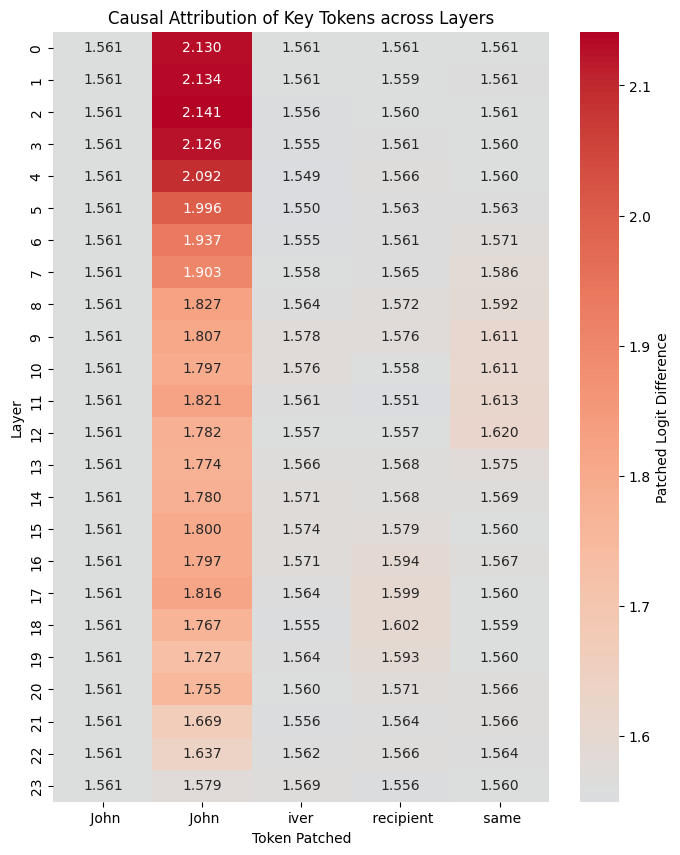

In [ ]:
import torch
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Focus on the key name tokens and comparison positions
target_positions = [4, 9, 13, 15, 17]
target_labels = [token_labels[p] for p in target_positions]

sweep_results = torch.zeros((n_layers, len(target_positions)))

with torch.no_grad():
    for l in range(n_layers):
        for idx, pos in enumerate(target_positions):
            patched_logits = model.run_with_hooks(
                corrupt_tokens,
                fwd_hooks=[(
                    f"blocks.{l}.hook_resid_pre",
                    patch_residual(clean_cache, l, pos)
                )]
            )
            patched_ld = (
                patched_logits[0, answer_pos, yes_id]
                - patched_logits[0, answer_pos, no_id]
            ).item()
            sweep_results[l, idx] = patched_ld

# Plot the focused heatmap
plt.figure(figsize=(8, 10))
sns.heatmap(
    sweep_results.numpy(),
    xticklabels=target_labels,
    yticklabels=list(range(n_layers)),
    cmap="coolwarm",
    center=corrupt_ld.item(),
    annot=True,
    fmt=".3f",
    cbar_kws={'label': 'Patched Logit Difference'}
)
plt.title("Causal Attribution of Key Tokens across Layers")
plt.xlabel("Token Patched")
plt.ylabel("Layer")
plt.show()

### Comparing the Causal Influence of 'John' vs 'Mary' Tokens

To explicitly relate the behaviors of **`" John"`** (the first name, position 4) and **`" Mary"`** / **`" John"`** (the second name, position 9), we will trace their logit differences side-by-side across all layers. This will show exactly where in the network the distinction between the identical names (John -> John) versus different names (John -> Mary) is computed.

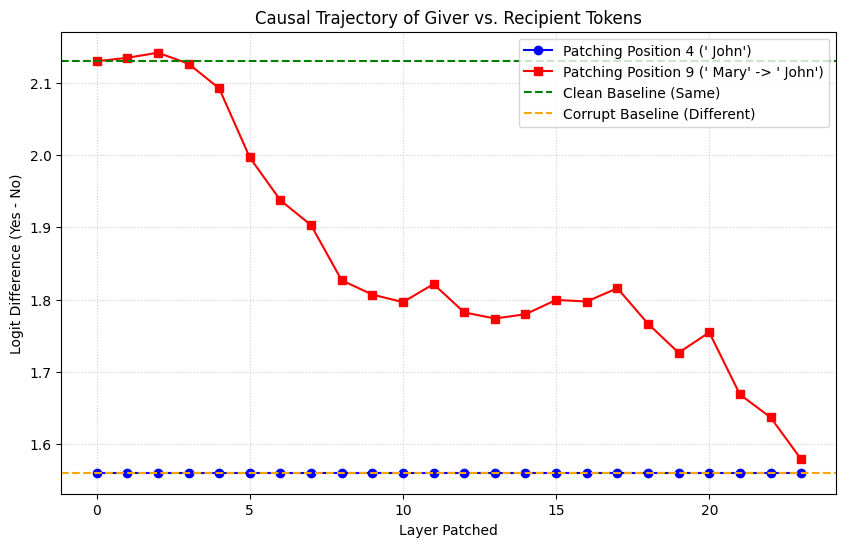

In [ ]:
import torch
import matplotlib.pyplot as plt

# Positions of interests
pos_first_john = 4
pos_second_name = 9

first_john_results = []
second_name_results = []

with torch.no_grad():
    for l in range(n_layers):
        # Patch first 'John' (Position 4)
        logits_first = model.run_with_hooks(
            corrupt_tokens,
            fwd_hooks=[(
                f"blocks.{l}.hook_resid_pre",
                patch_residual(clean_cache, l, pos_first_john)
            )]
        )
        ld_first = (logits_first[0, answer_pos, yes_id] - logits_first[0, answer_pos, no_id]).item()
        first_john_results.append(ld_first)

        # Patch second name (Position 9: 'John' in clean, 'Mary' in corrupt)
        logits_second = model.run_with_hooks(
            corrupt_tokens,
            fwd_hooks=[(
                f"blocks.{l}.hook_resid_pre",
                patch_residual(clean_cache, l, pos_second_name)
            )]
        )
        ld_second = (logits_second[0, answer_pos, yes_id] - logits_second[0, answer_pos, no_id]).item()
        second_name_results.append(ld_second)

# Plot the comparison trajectory
plt.figure(figsize=(10, 6))
plt.plot(range(n_layers), first_john_results, label="Patching Position 4 (' John')", marker='o', color='blue')
plt.plot(range(n_layers), second_name_results, label="Patching Position 9 (' Mary' -> ' John')", marker='s', color='red')
plt.axhline(y=clean_ld.item(), color='green', linestyle='--', label='Clean Baseline (Same)')
plt.axhline(y=corrupt_ld.item(), color='orange', linestyle='--', label='Corrupt Baseline (Different)')

plt.title("Causal Trajectory of Giver vs. Recipient Tokens")
plt.xlabel("Layer Patched")
plt.ylabel("Logit Difference (Yes - No)")
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()

### Measuring Direct Logit Attribution (DLA) of Attention Heads

To see which attention heads directly write to the output direction of (`' yes'` - `' no'`), we project the output of each head at the final sequence position (`answer_pos`) onto the final Layer Norm and Unembedding direction for those specific tokens.

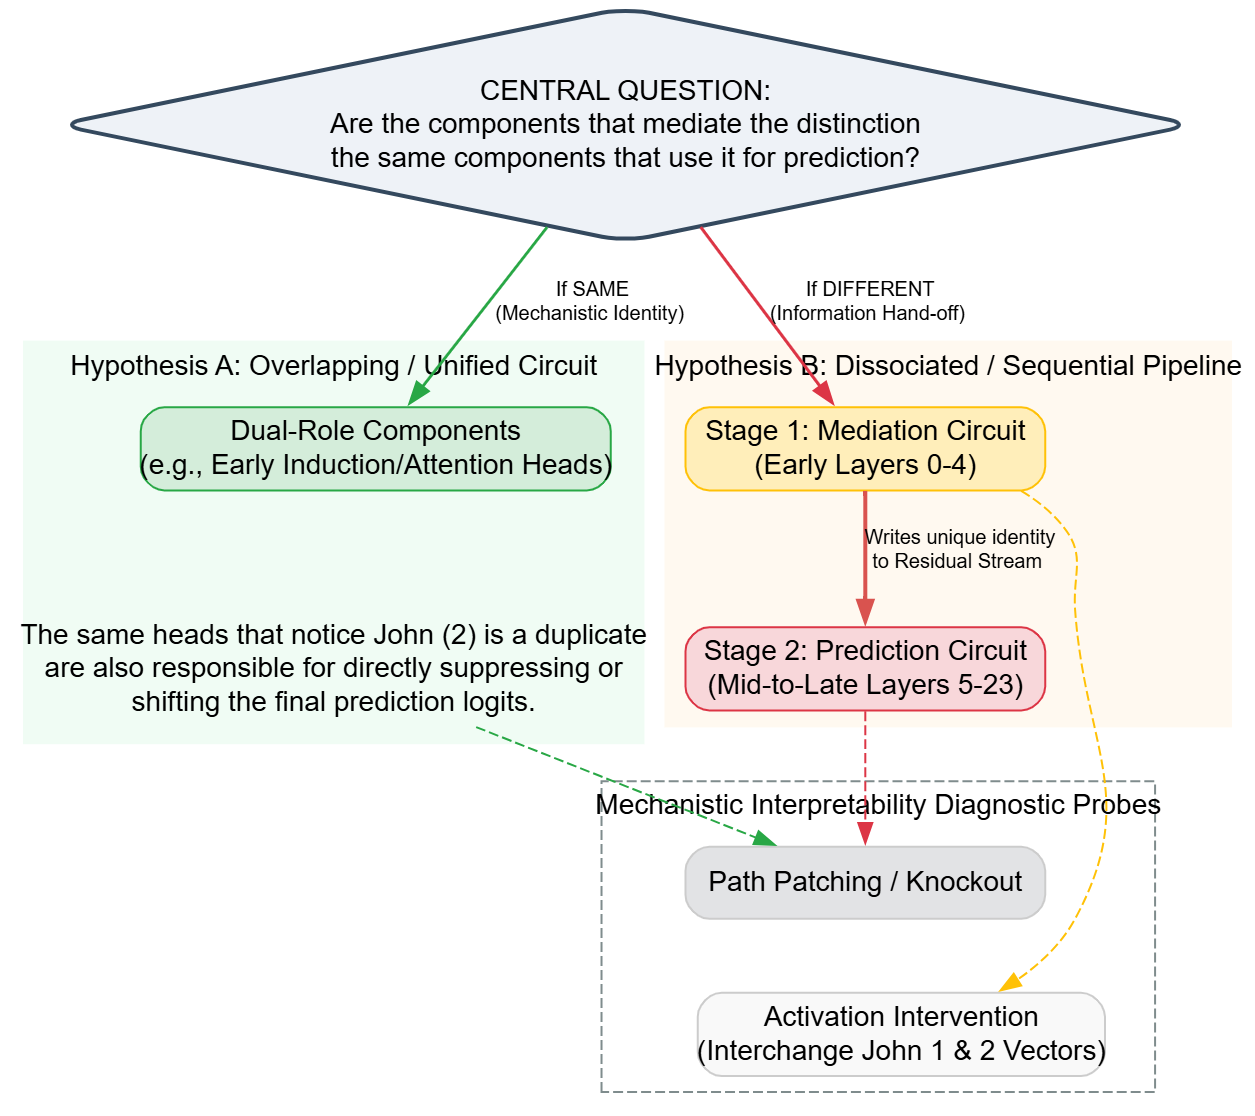

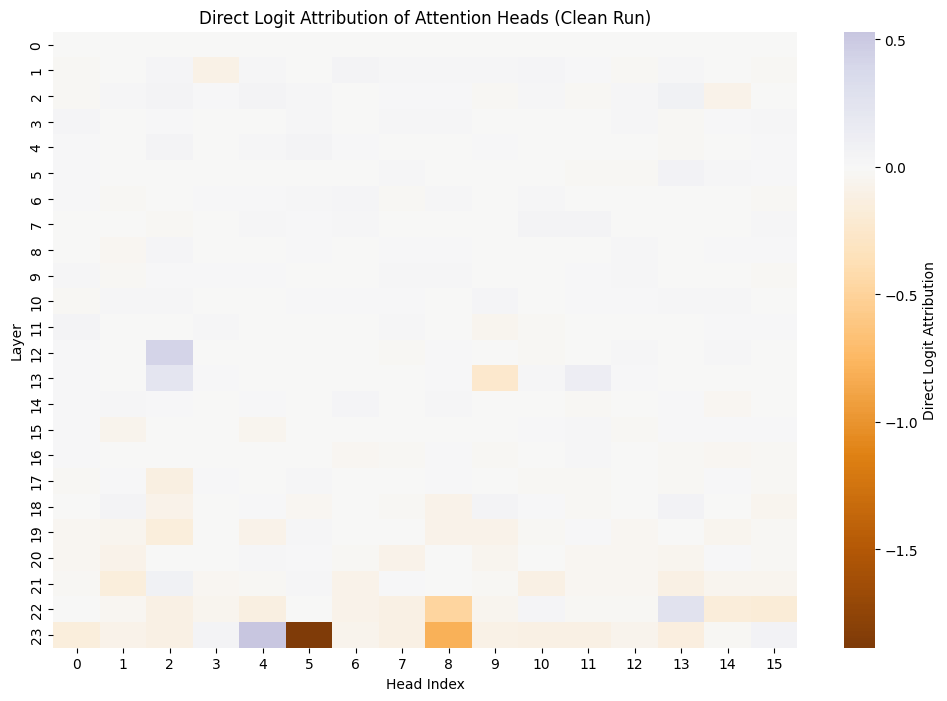

In [ ]:
import torch
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Get the unembedding weight vectors for yes and no
W_U = model.W_U
yes_unembed = W_U[:, yes_id]
no_unembed = W_U[:, no_id]
logit_diff_direction = yes_unembed - no_unembed

# We will use the cache from the clean run to compute direct attribution
# of each attention head output (hook_result)
dla_results = torch.zeros((n_layers, model.cfg.n_heads))

for l in range(n_layers):
    # Get hook_z (shape: [batch, seq_len, head_index, d_head])
    z = clean_cache[f"blocks.{l}.attn.hook_z"][0, answer_pos, :, :]
    # Get W_O (shape: [num_heads, d_head, d_model])
    W_O = model.blocks[l].attn.W_O

    # Calculate hook_result manually: project z through W_O for each head
    # Shape: [head_index, d_model]
    head_outputs = torch.einsum("hd, hdm -> hm", z, W_O)

    # Scale head outputs by final layer norm scale factor to keep attribution precise
    scaled_outputs = head_outputs / clean_cache["scale"][0, answer_pos, 0]

    for h in range(model.cfg.n_heads):
        dla_results[l, h] = torch.dot(scaled_outputs[h], logit_diff_direction).item()

# Plot the Direct Logit Attribution map
plt.figure(figsize=(12, 8))
sns.heatmap(
    dla_results.numpy(),
    cmap="PuOr",
    center=0.0,
    annot=False,
    cbar_kws={'label': 'Direct Logit Attribution'}
)
plt.title("Direct Logit Attribution of Attention Heads (Clean Run)")
plt.xlabel("Head Index")
plt.ylabel("Layer")
plt.show()

### Attention Head Ablation & Recovery Matrix

To see how information moves to the final token, we can perform **ablation** (zeroing out the output of specific attention heads) and measure the impact on the model's performance via a **Recovery Matrix**.

In [ ]:
import torch
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

n_layers = model.cfg.n_layers
n_heads = model.cfg.n_heads

# Initialize matrix to store ablated logit differences
ablation_results = torch.zeros((n_layers, n_heads))

# Baseline metrics
clean_val = clean_ld.item()
corrupt_val = corrupt_ld.item()
baseline_diff = clean_val - corrupt_val

print(f"Clean Baseline: {clean_val:.4f}")
print(f"Corrupt Baseline: {corrupt_val:.4f}")

# We will loop over each layer and head, ablate its hook_z output, and record the new logit difference
for l in range(n_layers):
    for h in range(n_heads):
        # Define hook function to ablate a specific head's output
        def ablate_head_hook(z, hook):
            # z shape: [batch, seq_len, head_index, d_head]
            z[:, :, h, :] = 0.0
            return z

        # Run with ablation hook
        ablated_logits = model.run_with_hooks(
            clean_tokens,  # Run on clean tokens to see how performance drops towards corrupt baseline
            fwd_hooks=[(
                f"blocks.{l}.attn.hook_z",
                ablate_head_hook
            )]
        )

        # Compute Logit Difference
        ablated_ld = (
            ablated_logits[0, answer_pos, yes_id]
            - ablated_logits[0, answer_pos, no_id]
        ).item()

        ablation_results[l, h] = ablated_ld

# Calculate the Recovery Matrix
# 1.0 means performance matches clean run (no effect from ablation)
# 0.0 means performance drops to corrupt run level (critical head)
recovery_matrix = (ablation_results - corrupt_val) / baseline_diff

print("Ablation sweep completed successfully.")

Clean Baseline: 2.1295
Corrupt Baseline: 1.5606
Ablation sweep completed successfully.


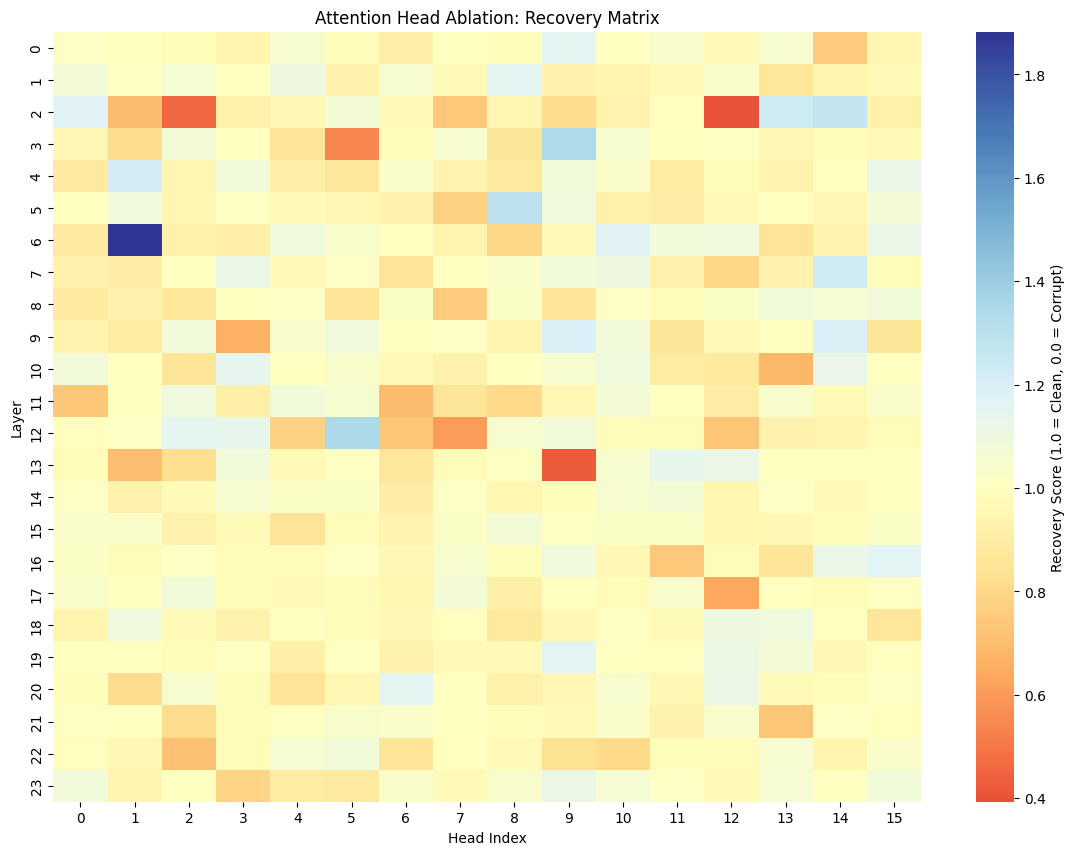

In [ ]:
# Plot the Recovery Matrix
plt.figure(figsize=(14, 10))
sns.heatmap(
    recovery_matrix.numpy(),
    cmap="RdYlBu",
    center=1.0,
    annot=False,
    cbar_kws={'label': 'Recovery Score (1.0 = Clean, 0.0 = Corrupt)'}
)
plt.title("Attention Head Ablation: Recovery Matrix")
plt.xlabel("Head Index")
plt.ylabel("Layer")
plt.show()

In [ ]:
# Identify the top 5 most critical heads (lowest recovery score)
flat_recovery = recovery_matrix.flatten()
top_critical_indices = torch.argsort(flat_recovery)[:5]

print("Top 5 most critical attention heads for distinguishing identical entities:")
for idx in top_critical_indices:
    layer_idx = int(idx // n_heads)
    head_idx = int(idx % n_heads)
    score = recovery_matrix[layer_idx, head_idx].item()
    original_ld_change = ablation_results[layer_idx, head_idx].item()
    print(f"Layer {layer_idx}, Head {head_idx} -> Recovery Score: {score:.4f} (Logit Diff: {original_ld_change:.4f})")

Top 5 most critical attention heads for distinguishing identical entities:
Layer 2, Head 12 -> Recovery Score: 0.3934 (Logit Diff: 1.7844)
Layer 13, Head 9 -> Recovery Score: 0.4195 (Logit Diff: 1.7992)
Layer 2, Head 2 -> Recovery Score: 0.4538 (Logit Diff: 1.8188)
Layer 3, Head 5 -> Recovery Score: 0.5442 (Logit Diff: 1.8702)
Layer 12, Head 7 -> Recovery Score: 0.6075 (Logit Diff: 1.9062)


### Visualizing the Duplicate Detection Circuit (Attention Patterns)

We will plot the attention patterns of the critical early heads we discovered (`L2H12`, `L2H2`, and `L3H5`) to see if they are actively attending from the second occurrence of "John" back to the first "John".

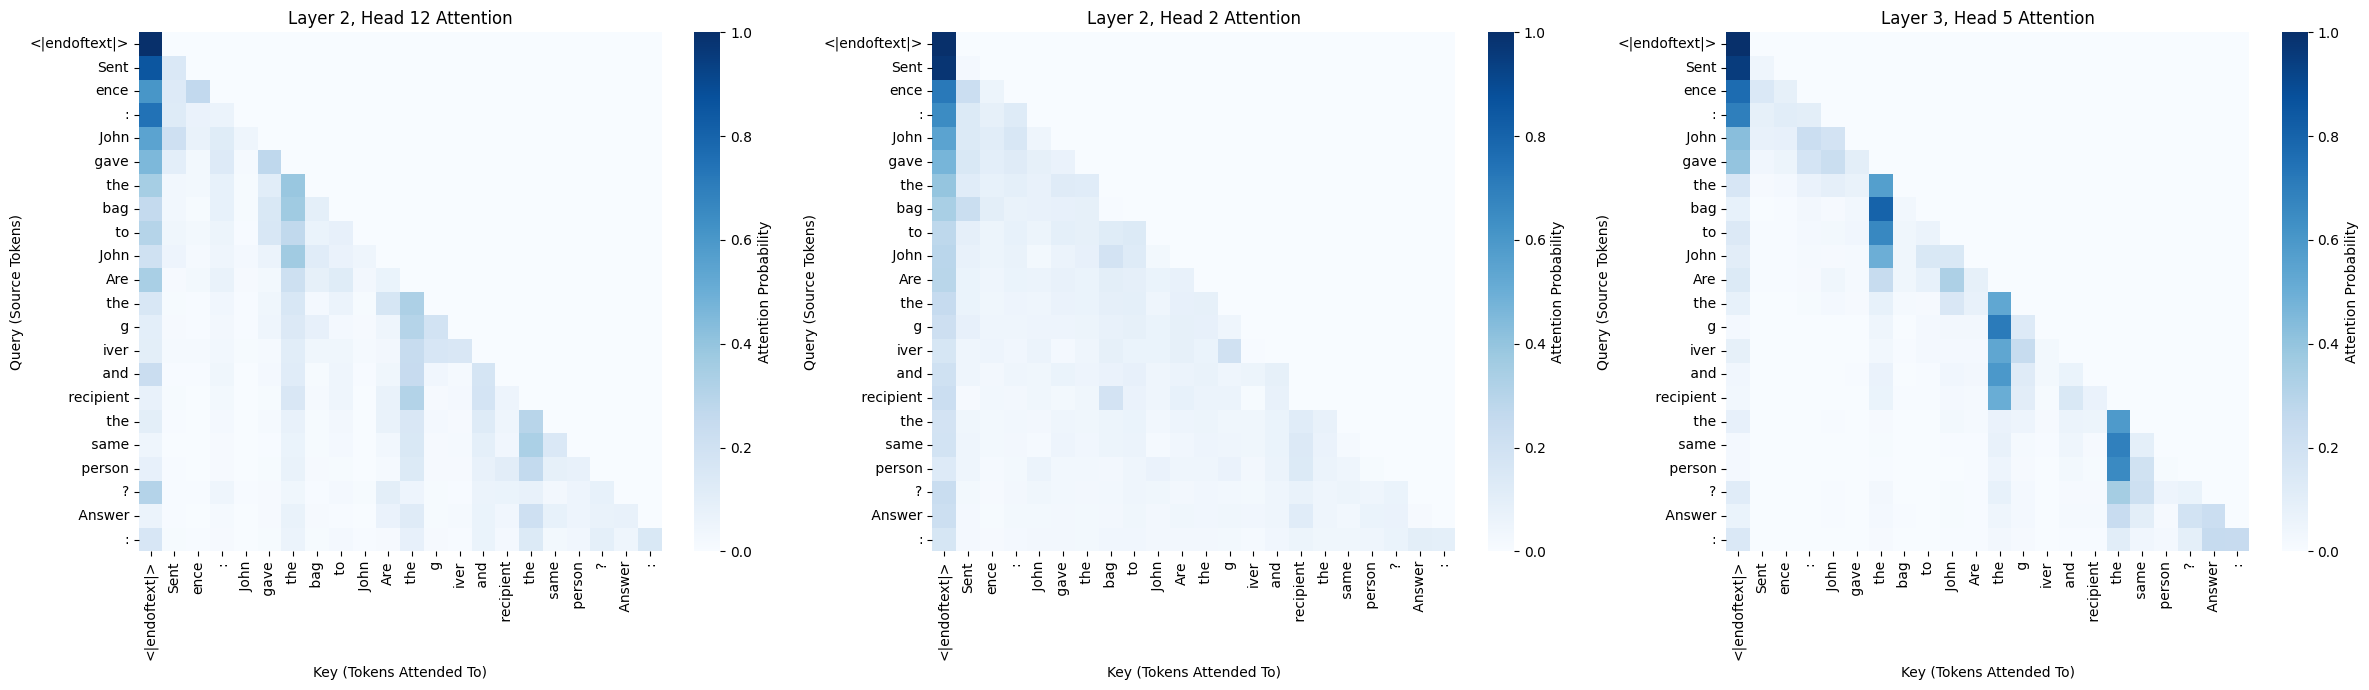

In [ ]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns

# Get tokens to label axes
tokens_str = model.to_str_tokens(clean_tokens[0])

# Heads to visualize
heads_to_visualize = [(2, 12), (2, 2), (3, 5)]

fig, axes = plt.subplots(1, 3, figsize=(24, 7))

for idx, (layer_idx, head_idx) in enumerate(heads_to_visualize):
    # Extract attention pattern: Shape [batch, num_heads, seq_len, seq_len]
    attn_pattern = clean_cache[f"blocks.{layer_idx}.attn.hook_pattern"][0, head_idx].detach().cpu().numpy()

    sns.heatmap(
        attn_pattern,
        xticklabels=tokens_str,
        yticklabels=tokens_str,
        cmap="Blues",
        ax=axes[idx],
        cbar_kws={'label': 'Attention Probability'}
    )
    axes[idx].set_title(f"Layer {layer_idx}, Head {head_idx} Attention")
    axes[idx].set_xlabel("Key (Tokens Attended To)")
    axes[idx].set_ylabel("Query (Source Tokens)")

plt.tight_layout()
plt.show()

### Attention Head Mean Ablation & Recovery Matrix

We will now run a full sweep across all layers and heads. For each attention head, we will ablate its output ($z$) by replacing it with the mean activation of that specific head calculated across both the clean and corrupt caches. We will then plot the resulting recovery scores as a heatmap to see how critical each head is under mean ablation.

In [ ]:
import torch
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

n_layers = model.cfg.n_layers
n_heads = model.cfg.n_heads

# Initialize matrix to store mean-ablated logit differences
mean_ablation_results = torch.zeros((n_layers, n_heads))

# Baseline metrics
clean_val = clean_ld.item()
corrupt_val = corrupt_ld.item()
baseline_diff = clean_val - corrupt_val

print("Running full mean-ablation sweep across all heads...")

# Loop over each layer and head to perform mean ablation
for l in range(n_layers):
    hook_name = f"blocks.{l}.attn.hook_z"
    clean_act = clean_cache[hook_name]
    corrupt_act = corrupt_cache[hook_name]
    # Calculate mean activation for this entire layer's hook_z
    mean_layer_act = (clean_act + corrupt_act) / 2.0

    for h in range(n_heads):
        # Define hook function to mean-ablate a specific head's output
        def mean_ablate_head_hook(z, hook, head_idx=h, mean_val=mean_layer_act):
            # Replace activations of head_idx with its mean across clean/corrupt states
            z[:, :, head_idx, :] = mean_val[:, :, head_idx, :]
            return z

        # Run model with the mean-ablation hook
        ablated_logits = model.run_with_hooks(
            clean_tokens,
            fwd_hooks=[(hook_name, mean_ablate_head_hook)]
        )

        # Compute Logit Difference
        ablated_ld = (
            ablated_logits[0, answer_pos, yes_id]
            - ablated_logits[0, answer_pos, no_id]
        ).item()

        mean_ablation_results[l, h] = ablated_ld

# Calculate the Recovery Matrix under Mean Ablation
# 1.0 means performance matches clean run (no effect from mean ablation)
# 0.0 means performance drops to corrupt run level
mean_recovery_matrix = (mean_ablation_results - corrupt_val) / baseline_diff

print("Mean ablation sweep completed successfully.")

Running full mean-ablation sweep across all heads...
Mean ablation sweep completed successfully.


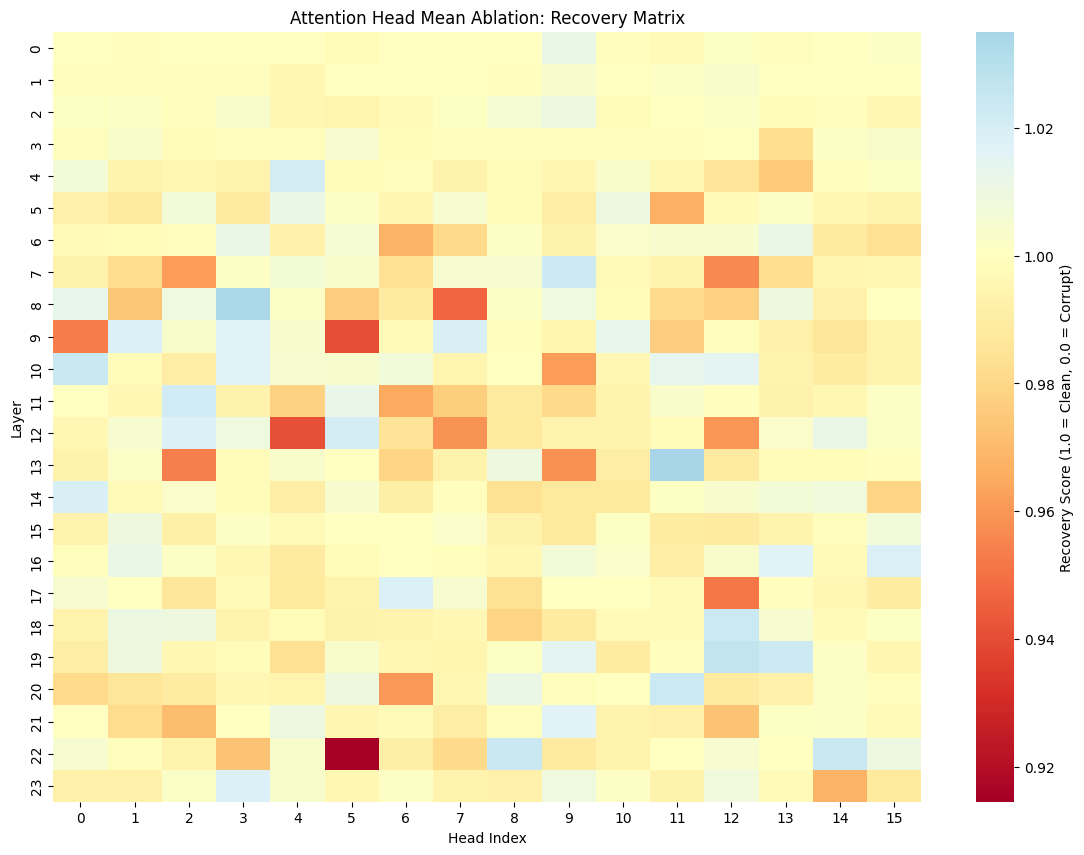

In [ ]:
# Plot the Mean Ablation Recovery Matrix
plt.figure(figsize=(14, 10))
sns.heatmap(
    mean_recovery_matrix.numpy(),
    cmap="RdYlBu",
    center=1.0,
    annot=False,
    cbar_kws={'label': 'Recovery Score (1.0 = Clean, 0.0 = Corrupt)'}
)
plt.title("Attention Head Mean Ablation: Recovery Matrix")
plt.xlabel("Head Index")
plt.ylabel("Layer")
plt.show()

#### See what does `L22H5` is doing in the model.